# Microgrid Dispatch — Analysis

Loads saved results from `easy_model.py` and `hard_model.py`; never re-solves.  

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

sys.path.insert(0, "src")
from config import (
    DT, E_CAP, D_OFF, D_ON, C_DEG, RESULTS_DIR,
)
from easy_model import load as load_easy
from hard_model import load as load_hard

plt.rcParams.update({"figure.dpi": 130, "axes.grid": True, "grid.alpha": 0.3})

easy = load_easy()
hard = load_hard()
df   = easy.df          # shared 8,760-row input table

T     = len(df)
L     = df["L"].values
S     = df["S"].values
c     = df["c"].values
month = df["month"].values
on    = df["period"].values == 2

## 1. Baselines

Scenario A (grid only) and B (PV + grid, no battery) are computed analytically — no solver needed.

In [2]:
def demand_charge(g_arr):
    """Recompute annual demand charge from an hourly grid-import array."""
    pk_off = sum(g_arr[(month == m) & ~on].max() for m in range(1, 13))
    pk_on  = sum(g_arr[(month == m) &  on].max() for m in range(1, 13))
    return D_OFF * pk_off + D_ON * pk_on

# A: grid only — buy everything, no PV, no battery
g_A        = L.copy()
energy_A   = float(c @ g_A * DT)
demand_A   = demand_charge(g_A)
cost_A     = energy_A + demand_A

# B: PV + grid, no battery — curtail surplus solar, buy the rest
g_B        = np.maximum(L - S, 0.0)
energy_B   = float(c @ g_B * DT)
demand_B   = demand_charge(g_B)
cost_B     = energy_B + demand_B

print(f"A  grid only      : ${cost_A:>10,.2f}  (energy ${energy_A:,.2f}  demand ${demand_A:,.2f})")
print(f"B  PV + grid      : ${cost_B:>10,.2f}  (energy ${energy_B:,.2f}  demand ${demand_B:,.2f})")
print(f"C  easy model     : ${easy.cost:>10,.2f}  (energy ${easy.energy_bill:,.2f}  demand ${easy.demand_bill:,.2f})")
print(f"D  hard model     : ${hard.cost:>10,.2f}  (energy ${hard.energy_bill:,.2f}  demand ${hard.demand_bill:,.2f}  wear ${hard.wear_bill:,.2f})")

A  grid only      : $ 72,588.75  (energy $41,643.76  demand $30,944.99)
B  PV + grid      : $ 56,002.45  (energy $25,799.86  demand $30,202.60)
C  easy model     : $ 34,201.73  (energy $19,637.57  demand $14,564.16)
D  hard model     : $ 41,224.77  (energy $21,704.12  demand $14,921.70  wear $4,598.96)


## 2. Cost comparison table

In [3]:
scenarios = {
    "A  Grid only":    {"Total": cost_A,     "Energy": energy_A,          "Demand": demand_A,          "Wear": 0.0},
    "B  PV + grid":    {"Total": cost_B,     "Energy": energy_B,          "Demand": demand_B,          "Wear": 0.0},
    "C  Easy (LP)":    {"Total": easy.cost,  "Energy": easy.energy_bill,  "Demand": easy.demand_bill,  "Wear": 0.0},
    "D  Hard (MILP)": {"Total": hard.cost,  "Energy": hard.energy_bill,  "Demand": hard.demand_bill,  "Wear": hard.wear_bill},
}

tbl = pd.DataFrame(scenarios).T
tbl["vs A ($)"]  = tbl["Total"] - cost_A
tbl["vs A (%)"]  = 100 * (tbl["Total"] - cost_A) / cost_A
tbl.style.format({
    "Total": "${:,.2f}", "Energy": "${:,.2f}", "Demand": "${:,.2f}", "Wear": "${:,.2f}",
    "vs A ($)": "${:+,.2f}", "vs A (%)": "{:+.1f}%",
})

,Total,Energy,Demand,Wear,vs A ($),vs A (%)
A Grid only,"$72,588.75","$41,643.76","$30,944.99",$0.00,$+0.00,+0.0%
B PV + grid,"$56,002.45","$25,799.86","$30,202.60",$0.00,"$-16,586.30",-22.8%
C Easy (LP),"$34,201.73","$19,637.57","$14,564.16",$0.00,"$-38,387.02",-52.9%
D Hard (MILP),"$41,224.77","$21,704.12","$14,921.70","$4,598.96","$-31,363.98",-43.2%


## 3. Price of realism

In [4]:
por        = hard.cost - easy.cost
por_pct    = 100 * por / easy.cost
wear_share = hard.wear_bill
ops_share  = (hard.energy_bill + hard.demand_bill) - (easy.energy_bill + easy.demand_bill)

# Battery gross savings: how much did each model save vs scenario B (PV+grid, no battery)
batt_savings_easy = cost_B - easy.cost
batt_savings_hard = cost_B - hard.cost

print(f"Price of realism (D - C)  : ${por:,.2f}  ({por_pct:.1f}% of easy cost)")
print(f"  of which wear           : ${wear_share:,.2f}")
print(f"  of which extra ops cost : ${ops_share:,.2f}")
print()
print(f"Battery gross savings vs B:")
print(f"  Easy model saves        : ${batt_savings_easy:,.2f}")
print(f"  Hard model saves        : ${batt_savings_hard:,.2f}")

# Split battery savings into energy-bill and demand-charge components
print()
print("Hard model savings breakdown vs B:")
print(f"  Energy bill saving      : ${energy_B - hard.energy_bill:,.2f}")
print(f"  Demand charge saving    : ${demand_B - hard.demand_bill:,.2f}")
print(f"  Less wear cost          : -${hard.wear_bill:,.2f}")
print(f"  Net saving              : ${batt_savings_hard:,.2f}")

Price of realism (D - C)  : $7,023.04  (20.5% of easy cost)
  of which wear           : $4,598.96
  of which extra ops cost : $2,424.08

Battery gross savings vs B:
  Easy model saves        : $21,800.72
  Hard model saves        : $14,777.68

Hard model savings breakdown vs B:
  Energy bill saving      : $4,095.74
  Demand charge saving    : $15,280.90
  Less wear cost          : -$4,598.96
  Net saving              : $14,777.68


## 4. Weekly SOC and power profiles

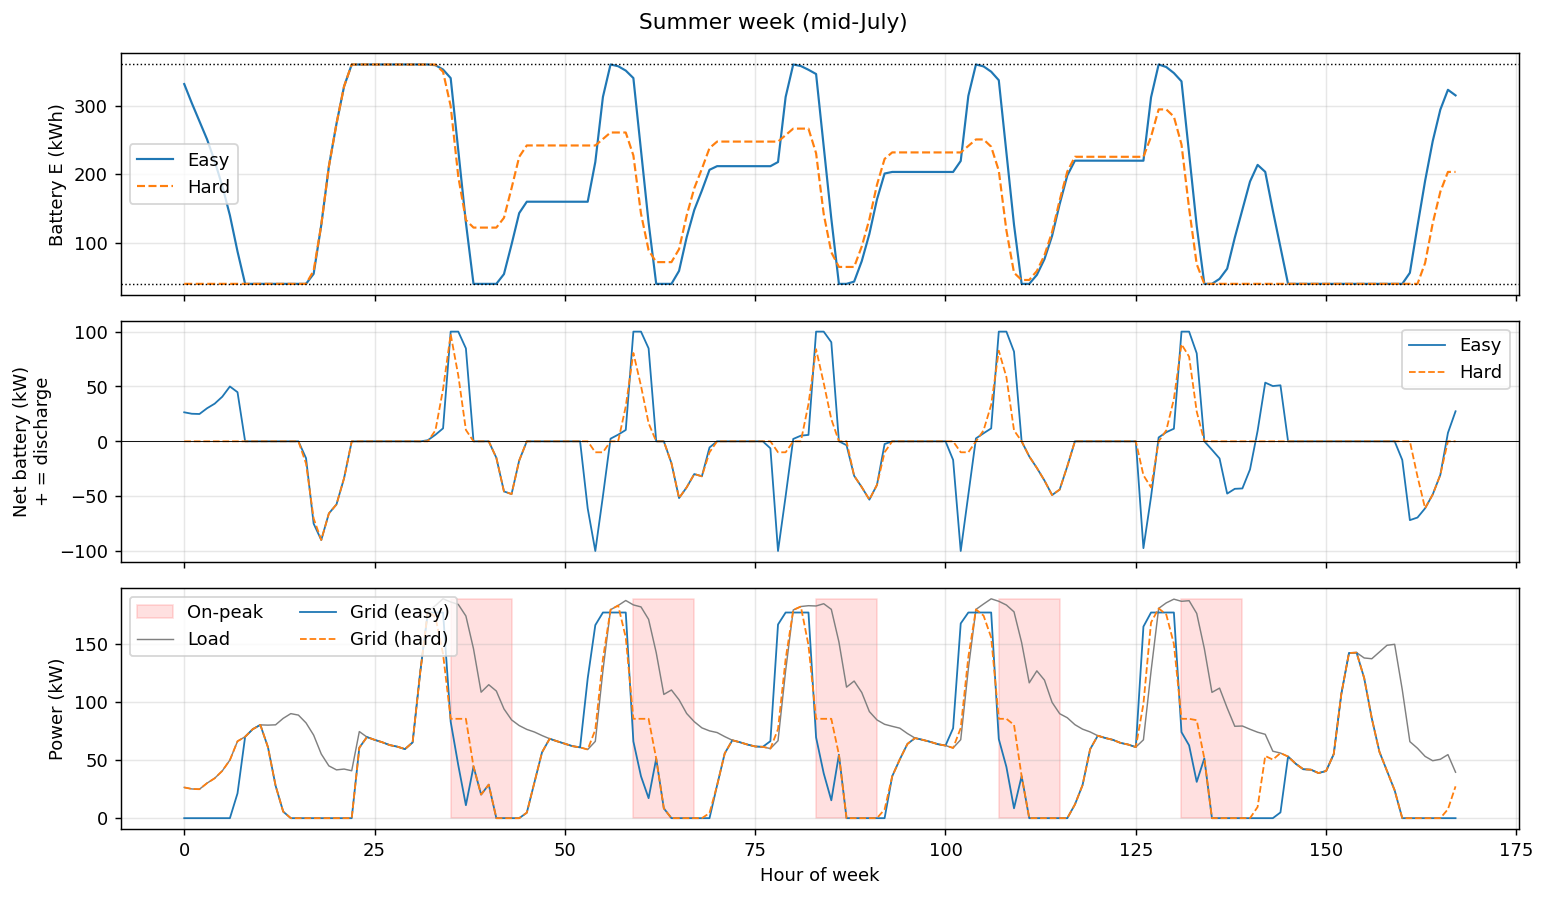

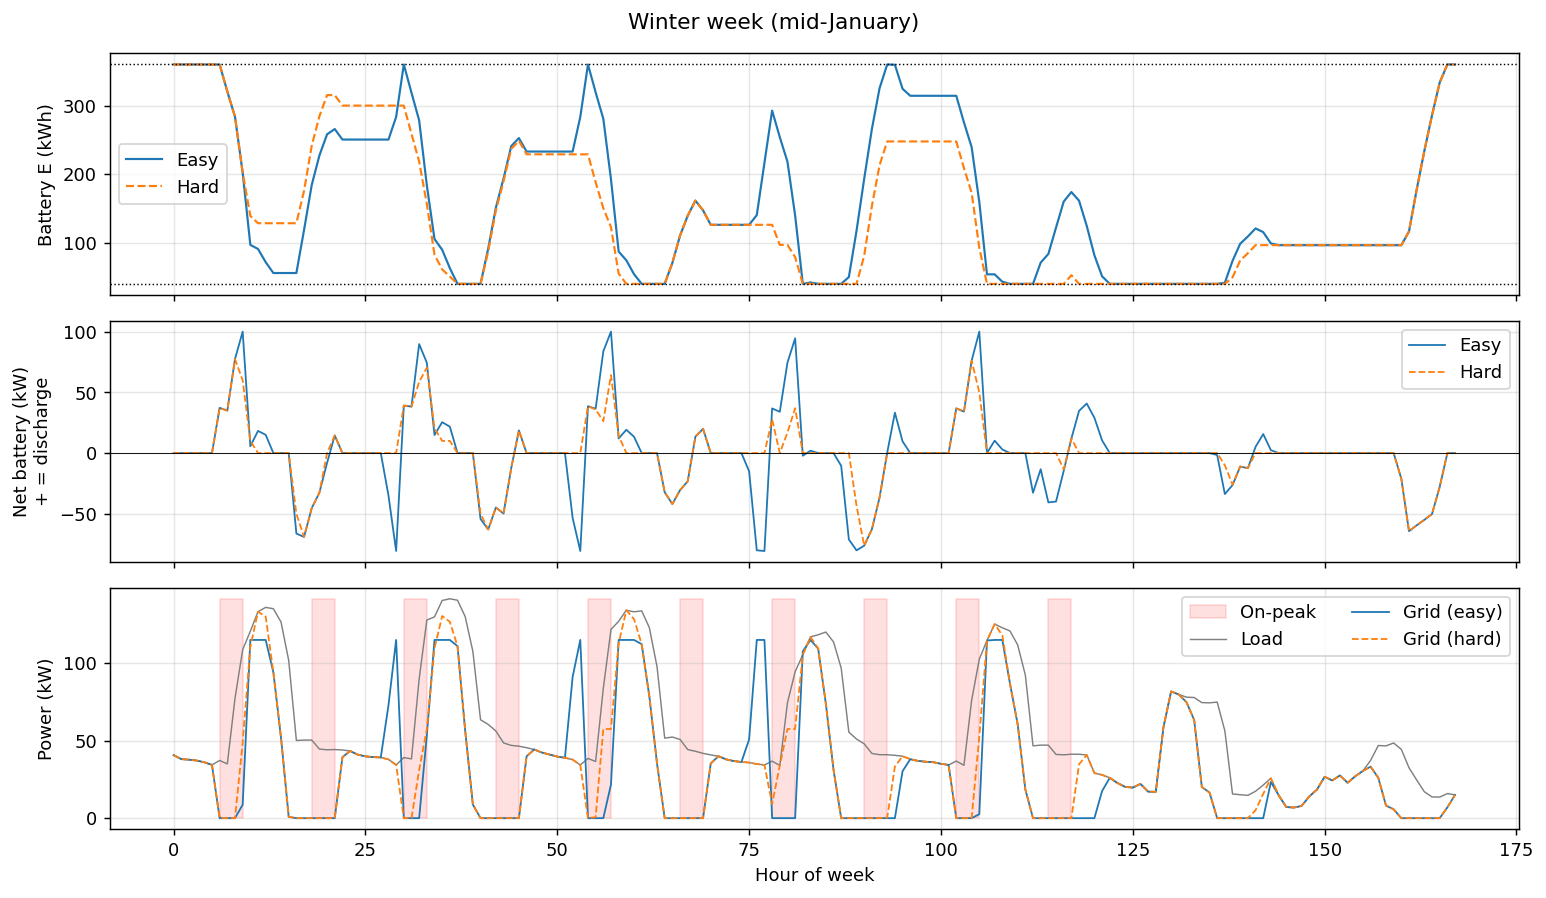

In [5]:
def week_slice(start_day):
    """Return hour indices for a 7-day window starting at start_day (0-indexed)."""
    h0 = start_day * 24
    return slice(h0, h0 + 168)

SUMMER_WEEK = week_slice(195)   # mid-July
WINTER_WEEK = week_slice(14)    # mid-January

def plot_week(sl, title):
    hrs = np.arange(168)
    fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    fig.suptitle(title)

    # SOC
    ax = axes[0]
    ax.plot(hrs, easy.E[sl.start : sl.stop],  label="Easy", lw=1.2)
    ax.plot(hrs, hard.E[sl.start : sl.stop],  label="Hard", lw=1.2, ls="--")
    ax.set_ylabel("Battery E (kWh)")
    ax.axhline(E_CAP * 0.1, color="k", ls=":", lw=0.8)
    ax.axhline(E_CAP * 0.9, color="k", ls=":", lw=0.8)
    ax.legend()

    # Net battery power (discharge positive)
    ax = axes[1]
    net_easy = easy.pd[sl] - easy.pc[sl]
    net_hard = hard.pd[sl] - hard.pc[sl]
    ax.plot(hrs, net_easy, label="Easy", lw=1.0)
    ax.plot(hrs, net_hard, label="Hard",  lw=1.0, ls="--")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylabel("Net battery (kW)\n+ = discharge")
    ax.legend()

    # Grid import vs TOU price shading
    ax = axes[2]
    on_sl = on[sl]
    ax.fill_between(hrs, 0, L[sl].max(), where=on_sl, alpha=0.12, color="red", label="On-peak")
    ax.plot(hrs, L[sl],       color="grey", lw=0.8, label="Load")
    ax.plot(hrs, easy.g[sl],  lw=1.0, label="Grid (easy)")
    ax.plot(hrs, hard.g[sl],  lw=1.0, ls="--", label="Grid (hard)")
    ax.set_ylabel("Power (kW)")
    ax.set_xlabel("Hour of week")
    ax.legend(ncol=2)

    plt.tight_layout()
    plt.show()

plot_week(SUMMER_WEEK, "Summer week (mid-July)")
plot_week(WINTER_WEEK, "Winter week (mid-January)")

## 5. Monthly cost breakdown

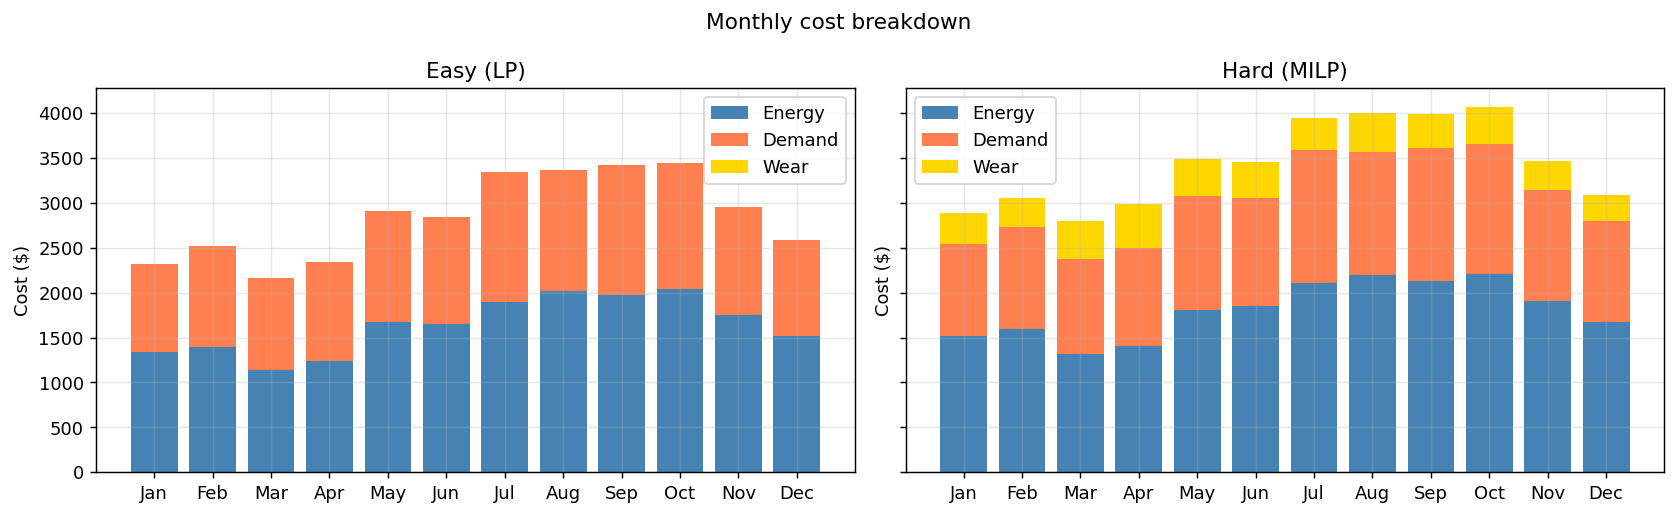

In [6]:
months = np.arange(1, 13)
month_labels = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

def monthly_breakdown(res, wear=False):
    """Return (energy, demand, wear) arrays by month, length 12."""
    energy = np.array([float(res.df["c"].values[month == m] @ res.g[month == m] * DT)
                       for m in months])
    pk_off = np.array([res.g[(month == m) & ~on].max() for m in months])
    pk_on  = np.array([res.g[(month == m) &  on].max() for m in months])
    demand = D_OFF * pk_off + D_ON * pk_on
    wear_m = (np.array([(res.pc[month == m] + res.pd[month == m]).sum() * DT * C_DEG
                        for m in months]) if wear else np.zeros(12))
    return energy, demand, wear_m

e_e, d_e, _   = monthly_breakdown(easy)
e_h, d_h, w_h = monthly_breakdown(hard, wear=True)

x = np.arange(12)
w = 0.35
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, (e, d, w_arr, label) in zip(axes, [
    (e_e, d_e, np.zeros(12), "Easy (LP)"),
    (e_h, d_h, w_h,          "Hard (MILP)"),
]):
    ax.bar(x, e,       label="Energy",  color="steelblue")
    ax.bar(x, d,       label="Demand",  color="coral",   bottom=e)
    ax.bar(x, w_arr,   label="Wear",    color="gold",    bottom=e + d)
    ax.set_title(label)
    ax.set_xticks(x); ax.set_xticklabels(month_labels)
    ax.set_ylabel("Cost ($)")
    ax.legend()

plt.suptitle("Monthly cost breakdown")
plt.tight_layout()
plt.show()

## 6. Monthly peak grid draw

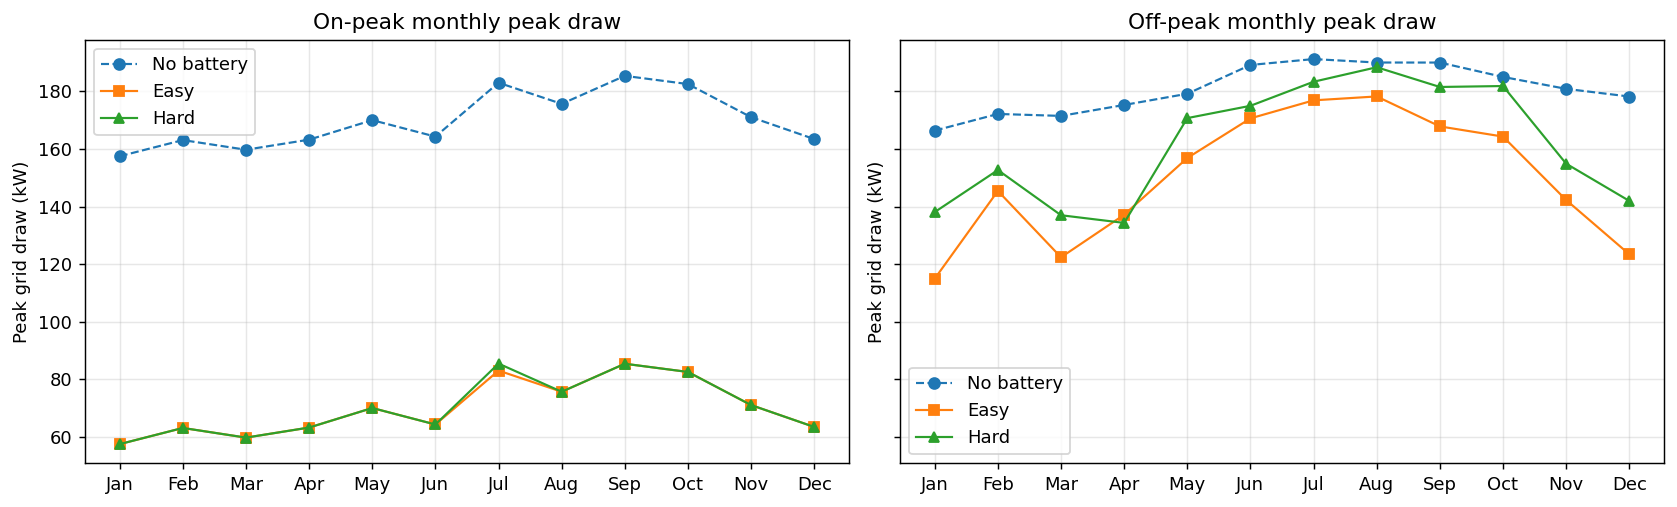

In [7]:
peak_B_on  = np.array([g_B[(month == m) &  on].max() for m in months])
peak_B_off = np.array([g_B[(month == m) & ~on].max() for m in months])

peak_e_on  = np.array([easy.g[(month == m) &  on].max() for m in months])
peak_e_off = np.array([easy.g[(month == m) & ~on].max() for m in months])

peak_h_on  = np.array([hard.g[(month == m) &  on].max() for m in months])
peak_h_off = np.array([hard.g[(month == m) & ~on].max() for m in months])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, (pB, pE, pH, period) in zip([ax1, ax2], [
    (peak_B_on,  peak_e_on,  peak_h_on,  "On-peak"),
    (peak_B_off, peak_e_off, peak_h_off, "Off-peak"),
]):
    ax.plot(month_labels, pB, "o--", label="No battery",  lw=1.2)
    ax.plot(month_labels, pE, "s-",  label="Easy",        lw=1.2)
    ax.plot(month_labels, pH, "^-",  label="Hard",        lw=1.2)
    ax.set_title(f"{period} monthly peak draw")
    ax.set_ylabel("Peak grid draw (kW)")
    ax.legend()

plt.tight_layout()
plt.show()

## 7. Solar use vs curtailment

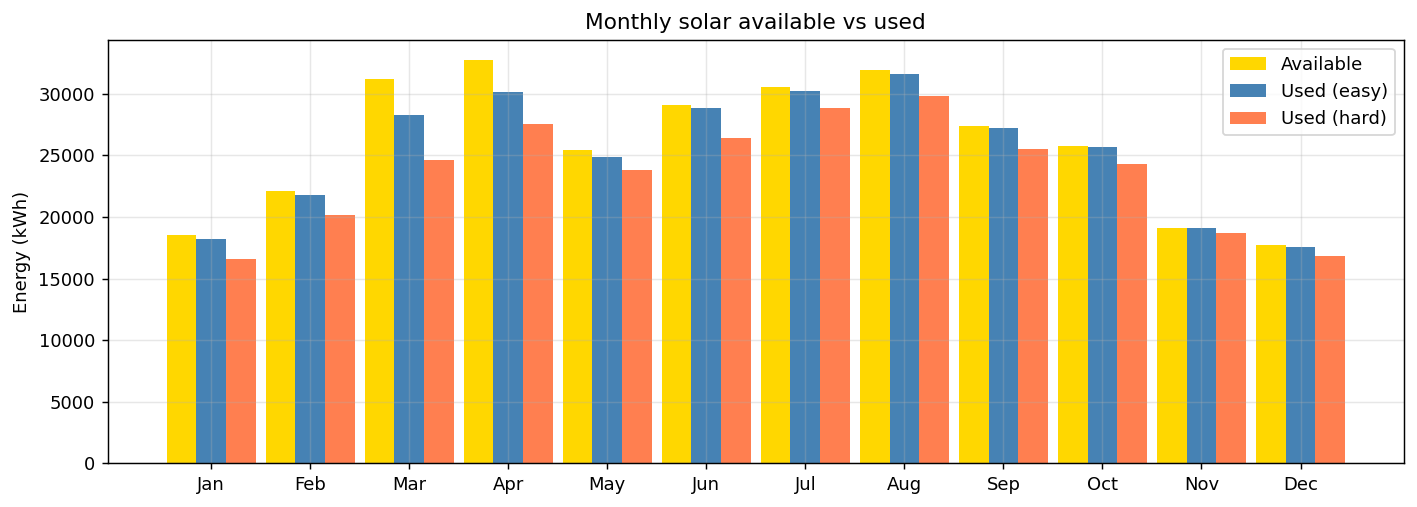

Easy: 8,130 kWh curtailed  (2.6%)
Hard: 28,355 kWh curtailed  (9.1%)


In [8]:
solar_avail = np.array([S[month == m].sum() for m in months])
solar_e     = np.array([easy.s[month == m].sum() for m in months])
solar_h     = np.array([hard.s[month == m].sum() for m in months])

x = np.arange(12)
w = 0.3
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - w, solar_avail,          w, label="Available",       color="gold")
ax.bar(x,     solar_e,              w, label="Used (easy)",     color="steelblue")
ax.bar(x + w, solar_h,              w, label="Used (hard)",     color="coral")
ax.set_xticks(x); ax.set_xticklabels(month_labels)
ax.set_ylabel("Energy (kWh)")
ax.set_title("Monthly solar available vs used")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Easy: {(S - easy.s).sum():,.0f} kWh curtailed  ({100*(S-easy.s).sum()/S.sum():.1f}%)")
print(f"Hard: {(S - hard.s).sum():,.0f} kWh curtailed  ({100*(S-hard.s).sum()/S.sum():.1f}%)")

## 8. Sensitivity: price of realism vs C_DEG

Re-costs the hard schedule at different wear rates without re-solving — shows how sensitive the gap is to the degradation assumption.

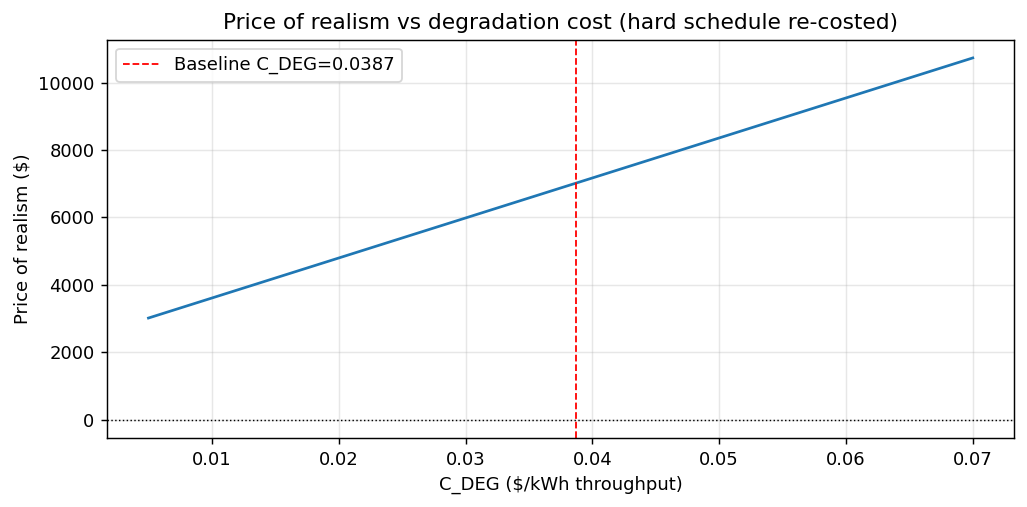

In [9]:
c_deg_vals = np.linspace(0.005, 0.07, 40)
throughput = (hard.pc + hard.pd).sum() * DT   # fixed schedule, vary only the wear price

hard_costs_recost = hard.energy_bill + hard.demand_bill + c_deg_vals * throughput
por_vals          = hard_costs_recost - easy.cost

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(c_deg_vals, por_vals, lw=1.5)
ax.axvline(C_DEG, color="red", ls="--", lw=1, label=f"Baseline C_DEG={C_DEG:.4f}")
ax.axhline(0,     color="k",   ls=":",  lw=0.8)
ax.set_xlabel("C_DEG ($/kWh throughput)")
ax.set_ylabel("Price of realism ($)")
ax.set_title("Price of realism vs degradation cost (hard schedule re-costed)")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Key numbers for the report

In [10]:
print("=" * 55)
print("Summary for report")
print("=" * 55)
print(f"  Annual load              : {L.sum():,.0f} kWh")
print(f"  Annual PV available      : {S.sum():,.0f} kWh")
print()
print(f"  Scenario A (grid only)   : ${cost_A:,.2f}")
print(f"  Scenario B (PV, no batt) : ${cost_B:,.2f}  saves ${cost_A-cost_B:,.2f} vs A")
print(f"  Scenario C (easy)        : ${easy.cost:,.2f}  saves ${cost_B-easy.cost:,.2f} vs B")
print(f"  Scenario D (hard)        : ${hard.cost:,.2f}  saves ${cost_B-hard.cost:,.2f} vs B")
print()
print(f"  Price of realism (D-C)   : ${hard.cost-easy.cost:,.2f}  ({100*(hard.cost-easy.cost)/easy.cost:.1f}% of C)")
print(f"    wear cost              : ${hard.wear_bill:,.2f}")
print(f"    extra ops              : ${(hard.energy_bill+hard.demand_bill)-(easy.energy_bill+easy.demand_bill):,.2f}")
print()
print(f"  Easy throughput          : {(easy.pc+easy.pd).sum()*DT:,.0f} kWh  ({(easy.pc+easy.pd).sum()*DT/(2*E_CAP):.0f} cycles)")
print(f"  Hard throughput          : {(hard.pc+hard.pd).sum()*DT:,.0f} kWh  ({(hard.pc+hard.pd).sum()*DT/(2*E_CAP):.0f} cycles)")
print("=" * 55)

Summary for report
  Annual load              : 701,806 kWh
  Annual PV available      : 311,674 kWh

  Scenario A (grid only)   : $72,588.75
  Scenario B (PV, no batt) : $56,002.45  saves $16,586.30 vs A
  Scenario C (easy)        : $34,201.73  saves $21,800.72 vs B
  Scenario D (hard)        : $41,224.77  saves $14,777.68 vs B

  Price of realism (D-C)   : $7,023.04  (20.5% of C)
    wear cost              : $4,598.96
    extra ops              : $2,424.08

  Easy throughput          : 209,879 kWh  (262 cycles)
  Hard throughput          : 118,683 kWh  (148 cycles)
